# AIDA 2156 Final Project – 04 Outliers, Feature Relationships and Sensitivity

**Data version 2** (`shared/synthetic-data/`): the official cleaned requests (cleaning version 1.1), with notebook 02's working calendar and notebook 03's comparisons. The answer key is not used.

**Question:** Do the findings of notebooks 02 and 03 hold when reasonable measurement and population choices change — in particular how after-hours submissions are handled and whether requests unfinished at the extract are included? Sections A and B first look at unusually long and short requests and at which workflow measures move together.

**Reference analysis.** Notebooks 02 and 03 exactly as run: working time (Monday–Friday, 08:00–16:30, excluding the simulated closure dates), so an after-hours submission starts counting at the next working moment; the 4,319 completed requests; and the 13 contrasts with 95% intervals from 2,000 employee resamples (seed 2026), with notebook 03's weights, workload cutoffs and rules. Part 1 reproduces these numbers exactly before any alternative is computed.

**Alternatives, fixed before any of their results are computed.** In the cleaned records only submissions happen outside working hours (656 of 4,364, 15.0%); every later workflow event falls within them. Each alternative changes one kind of thing:

| Scenario | What changes | Kind of change |
|:---|:---|:---|
| H1 Elapsed calendar time | Time is counted from the actual submission, through nights, weekends and closures (the requester's wait), in calendar days | Measurement |
| H2 Weekdays-only calendar | Monday–Friday 08:00–16:30 as before, but closure dates count as working days | Calendar |
| H3 Working-hours submissions only | After-hours submissions are left out | Population |
| H4 Narrower after-hours label | Only weekend and closure-date submissions count as after-hours; weekday submissions outside 08:00–16:30 count as working-hours submissions | Classification (after-hours contrasts only) |
| U1 Unfinished, time so far | The 45 unfinished requests are added with their working time up to the extract (29 Sep 2026, 17:00), a lower bound on their eventual time | Population |
| U2 Unfinished, longest | The 45 are added as longer than every completed request | Population |
| O1 Without the long tail | The requests above notebook 02's Tukey fence (11.68 working-day equivalents) are left out | Population |

**Rules for the unfinished requests.** For percentiles of all requests (completed and unfinished), U1 and U2 are bounds: the eventual value lies between them. Under U2 a percentile that falls among the unfinished requests is reported as "above the longest completed request". For contrasts, U1 and U2 are sensitivity scenarios, not bounds, because the unfinished requests may be spread unevenly between the compared groups. Under U2 every unfinished request is given one value that exceeds both the longest completed duration and the longest time so far of any unfinished request (the larger of the two plus one working-day equivalent), so it is longer than every completed request and consistent with every unfinished request's observed lower bound, and medians stay defined. U1 stage times are working time accumulated up to the extract, a different quantity from the stage shares of completed requests.

**Rules for the contrasts.** Each scenario uses notebook 03's 13 contrasts, estimators and bootstrap (2,000 employee resamples, seed 2026, intervals withheld when more than 1% of resamples are invalid). Workload cutoffs stay at notebook 03's values; stratum weights are the strata's shares of the scenario's own requests. Because those weights follow the scenario's population, a weighted contrast that differs from the reference can reflect both changed results within strata and a changed mix of strata; each scenario's strata, weights and coverage are therefore reported. A contrast that a scenario removes (the after-hours contrasts under H3) is "not applicable"; one whose groups both exist but no stratum has at least five requests on each side is "not estimable", with no estimate or interval.

**What counts as a change, fixed now.** For each contrast, three things are reported separately: whether the point estimate changes direction, how much it changes, and whether the interval's relation to zero changes (excludes zero ↔ includes zero). The full task-type ordering is reported; a swap between task types whose reference medians differ by less than 0.25 working-day equivalents is reported as a small swap, separately from changes that affect a written finding. Every written finding of notebooks 02 and 03 then gets one label: **stable** (no change in any applicable scenario), **depends on scenario** (named), **not applicable** (the scenario removes it) or **not comparable** (H1 sizes are in calendar days, so only direction and ordering are compared). Intervals are descriptive: no p-values are calculated and no difference is called significant.

All results describe generated data; patterns are associations, not causes.

In [1]:
import hashlib
import json
from datetime import datetime, time, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

DATA_VERSION = "2"
SD = Path("../../../shared/synthetic-data")          # data version 2
OUTPUT_DIR = Path("../outputs")
FIGURE_DIR = Path("../figures")

read = lambda path: pd.read_csv(path, dtype=str, keep_default_na=False)
sha = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()

requests = read(SD / "cleaning/output/requests_cleaned.csv")
cleaning_info = json.loads((SD / "cleaning/output/requests_cleaned_info.json").read_text())
assert sha(SD / "cleaning/output/requests_cleaned.csv") == cleaning_info["output_sha256"], \
    "The cleaned file doesn't match its cleaning record"

# Notebook 02's working calendar; the generator must be unchanged since then
calendar = json.loads((OUTPUT_DIR / "working_calendar.json").read_text())
assert sha(SD / "requests/generate_requests.py") == calendar["generator_sha256"], \
    "The generator has changed since notebook 02 saved the working calendar"
CLOSURES = {pd.Timestamp(d).date() for d in calendar["closure_dates"]}
DAY_START, DAY_END = time.fromisoformat(calendar["day_start"]), time.fromisoformat(calendar["day_end"])
DAY_HOURS = calendar["day_hours"]
EXTRACT_AT = pd.Timestamp(calendar["extract_at"])

# Inputs from notebooks 02 and 03 that this notebook must reproduce
inputs_03 = json.loads((OUTPUT_DIR / "analysis_inputs_03.json").read_text())
assert inputs_03["inputs_sha256"]["processing_times_completed.csv (notebook 02)"] == sha(OUTPUT_DIR / "processing_times_completed.csv")
assert inputs_03["inputs_sha256"]["working_calendar.json (notebook 02)"] == sha(OUTPUT_DIR / "working_calendar.json")
completed_02 = pd.read_csv(OUTPUT_DIR / "processing_times_completed.csv")
summary_02 = pd.read_csv(OUTPUT_DIR / "processing_time_summary.csv", index_col=0)
unfinished_02 = pd.read_csv(OUTPUT_DIR / "unfinished_requests.csv")
intervals_03 = pd.read_csv(OUTPUT_DIR / "contrast_intervals.csv")

TIME_COLUMNS = ["submitted_at", "info_complete_at", "assigned_at", "team_completed_at", "completion_confirmed_at"]
for c in TIME_COLUMNS:
    requests[c] = pd.to_datetime(requests[c].replace("", None), format="%Y-%m-%dT%H:%M")


def working_hours(start, end, closures=CLOSURES):
    # Notebook 02's working-time function, with the closure dates as a parameter (H2 passes an empty set)
    if pd.isna(start) or pd.isna(end):
        return np.nan
    if end < start:
        raise ValueError(f"End precedes start: {start} → {end}")
    if end == start:
        return 0.0
    total, day = 0.0, start.date()
    while day <= end.date():
        if day.weekday() < 5 and day not in closures:
            open_, close = datetime.combine(day, DAY_START), datetime.combine(day, DAY_END)
            total += max((min(end, close) - max(start, open_)).total_seconds(), 0) / 3600
        day += timedelta(days=1)
    return total


# Notebook 02's hand-made tests, plus the same closure case with closures counted as working days (H2)
T = pd.Timestamp
tests = pd.DataFrame([
    ("same working day", T("2026-03-03 09:00"), T("2026-03-03 11:30"), CLOSURES, 2.5),
    ("overnight", T("2026-03-03 15:30"), T("2026-03-04 09:00"), CLOSURES, 2.0),
    ("over a weekend", T("2026-03-06 16:00"), T("2026-03-09 08:30"), CLOSURES, 1.0),
    ("after-hours submission", T("2026-03-06 21:00"), T("2026-03-09 10:00"), CLOSURES, 2.0),
    ("over a simulated closure date (Fri 3 Apr 2026)", T("2026-04-02 16:00"), T("2026-04-06 09:00"), CLOSURES, 1.5),
    ("the same, closure counted as a working day (H2)", T("2026-04-02 16:00"), T("2026-04-06 09:00"), set(), 10.0),
    ("whole working day", T("2026-03-03 08:00"), T("2026-03-03 16:30"), CLOSURES, DAY_HOURS),
    ("start equals end", T("2026-03-03 10:00"), T("2026-03-03 10:00"), CLOSURES, 0.0),
], columns=["case", "start", "end", "closures", "expected_hours"])
assert T("2026-04-03").date() in CLOSURES
tests["calculated_hours"] = [working_hours(s, e, c) for s, e, c in zip(tests["start"], tests["end"], tests["closures"])]
assert np.isclose(tests["calculated_hours"], tests["expected_hours"]).all(), "The working-time function failed a test"

# Every workflow event other than submission falls inside working hours, as this notebook's design assumes
def outside_hours(t):
    t = t.dropna()
    return int(((t.dt.weekday >= 5) | t.dt.date.isin(CLOSURES) | ~t.dt.time.between(DAY_START, DAY_END, inclusive="both")).sum())
after_hours_events = {c: outside_hours(requests[c]) for c in TIME_COLUMNS}
assert all(v == 0 for c, v in after_hours_events.items() if c != "submitted_at"), "A later workflow event falls outside working hours"

print(f"Data version {DATA_VERSION}; cleaning version {cleaning_info['cleaning_version']}; extract {EXTRACT_AT:%Y-%m-%d %H:%M}")
print(f"{len(requests):,} cleaned requests; working-time function passes {len(tests)} hand-made tests (including H2's calendar)")
print("Events outside working hours, by timestamp:", after_hours_events)

Data version 2; cleaning version 1.1; extract 2026-09-29 17:00
4,364 cleaned requests; working-time function passes 8 hand-made tests (including H2's calendar)
Events outside working hours, by timestamp: {'submitted_at': 656, 'info_complete_at': 0, 'assigned_at': 0, 'team_completed_at': 0, 'completion_confirmed_at': 0}


## The reference, reproduced

The cell below rebuilds every request's durations and notebook 03's variables from the cleaned requests, using notebook 02's and notebook 03's rules unchanged: stage times and processing time in working-day equivalents, elapsed calendar days, working time so far for the unfinished requests, workload at assignment and its groups, the after-hours label and the intake channel. It then rebuilds notebook 03's 13 contrasts and their employee-bootstrap intervals, written as functions so every scenario can reuse them.

Before anything else is computed, the rebuilt values must match the saved outputs of notebooks 02 and 03, which the later sections use as the reference:

- each completed request's processing time, stage times and calendar days, and each unfinished request's time so far;
- notebook 02's overall summaries in working-day equivalents and calendar days (median, mean, quartiles, IQR, 90th percentile, longest, skew, Tukey fence and the number and share above it), its summaries by task type, its stage summary and its stage shares by task type;
- every contrast's point estimate, interval, number of valid resamples and whether its interval was withheld.

Counts must match exactly; other values are compared to within 1e-9, to allow only for floating-point rounding.

In [2]:
STAGES = ["info_check_h", "assignment_wait_h", "team_processing_h"]
TASK_ORDER = ["payroll_setup", "system_access", "workplace_access", "equipment_setup", "orientation_scheduling"]
r = requests.copy()
finished = r["team_completed_at"].notna()
all_stage_times = r[["submitted_at", "info_complete_at", "assigned_at", "team_completed_at"]].notna().all(axis=1)
r["group"] = np.select([finished & all_stage_times, ~finished], ["completed", "unfinished at extract"], default="other")
assert (r["group"] != "other").all(), "Every request should be completed with all stage times, or unfinished"


def durations(frame, closures=CLOSURES):
    # Stage, processing and time-so-far working durations under a closure calendar, in hours and working-day equivalents
    out = pd.DataFrame(index=frame.index)
    out["info_check_h"] = [working_hours(a, b, closures) for a, b in zip(frame["submitted_at"], frame["info_complete_at"])]
    out["assignment_wait_h"] = [working_hours(a, b, closures) for a, b in zip(frame["info_complete_at"], frame["assigned_at"])]
    out["team_processing_h"] = [working_hours(a, b, closures) for a, b in zip(frame["assigned_at"], frame["team_completed_at"])]
    out["processing_days"] = [working_hours(a, b, closures) / DAY_HOURS for a, b in zip(frame["submitted_at"], frame["team_completed_at"])]
    out["days_so_far"] = [working_hours(a, EXTRACT_AT, closures) / DAY_HOURS for a in frame["submitted_at"]]
    out["elapsed_calendar_days"] = (frame["team_completed_at"] - frame["submitted_at"]).dt.total_seconds() / 86400
    out["calendar_days_so_far"] = (EXTRACT_AT - frame["submitted_at"]).dt.total_seconds() / 86400
    return out


r = r.join(durations(r))
r["processing_h"] = r["processing_days"] * DAY_HOURS
STAGE_NAMES = {"info_check_h": "information check", "assignment_wait_h": "assignment wait", "team_processing_h": "team processing"}


def describe(values):
    # Notebook 02's summary of a duration
    values = values.dropna()
    q1, med, q3, p90 = values.quantile([0.25, 0.5, 0.75, 0.9])
    fence = q3 + 1.5 * (q3 - q1)
    return pd.Series({"requests": int(values.count()), "median": med, "mean": values.mean(), "q1": q1, "q3": q3,
                      "iqr": q3 - q1, "p90": p90, "max": values.max(), "skew": values.skew(), "tukey_fence": fence,
                      "unusually_long": int((values > fence).sum()), "unusually_long_%": 100 * (values > fence).mean()})


def stage_table(frame):
    # Notebook 02's stage summary: median and mean stage time, and each stage's share of total working time
    total = frame["processing_h"].sum()
    rows = {name: {"requests": len(frame), "median_days": (frame[col] / DAY_HOURS).median(),
                   "mean_days": (frame[col] / DAY_HOURS).mean(), "share_of_total_%": 100 * frame[col].sum() / total}
            for col, name in STAGE_NAMES.items()}
    return pd.DataFrame(rows).T


# Notebook 03's variables, unchanged
assigned = r[r["assigned_at"].notna()]
workload = {}
for team, g in assigned.groupby("responsible_team"):
    a = g["assigned_at"].to_numpy()
    done = g["team_completed_at"].fillna(pd.Timestamp.max).to_numpy()
    for rid, t in zip(g["request_id"], a):
        workload[rid] = int(((a < t) & (done > t)).sum())
r["workload_at_assignment"] = r["request_id"].map(workload)
r["intake_channel"] = r["intake_channel"].replace("", "unknown")
r["info_issue_at_intake"] = r["info_issue_at_intake"].map({"True": True, "False": False})
s = r["submitted_at"]
in_hours = s.dt.time.between(DAY_START, DAY_END, inclusive="both")
r["after_hours"] = (s.dt.weekday >= 5) | s.dt.date.isin(CLOSURES) | ~in_hours
r["after_hours_narrow"] = (s.dt.weekday >= 5) | s.dt.date.isin(CLOSURES)           # H4's label

# The completed requests, in notebook 02's row order (the bootstrap draws depend on it)
completed = r.set_index("request_id").loc[completed_02["request_id"]].reset_index()
Q1, Q3 = completed["workload_at_assignment"].quantile([0.25, 0.75])                # notebook 03's cutoffs, kept for every scenario
group_workload = lambda w: np.select([w <= Q1, w >= Q3], ["low", "high"], default="middle").astype(object)
r["workload_group"] = np.where(r["workload_at_assignment"].isna(), "not assigned", group_workload(r["workload_at_assignment"]))
completed["workload_group"] = group_workload(completed["workload_at_assignment"])
unfinished = r[r["group"] == "unfinished at extract"].copy()

# Reproduction of notebook 02
close = lambda a, b: np.allclose(np.asarray(a, dtype=float), np.asarray(b, dtype=float), rtol=0, atol=1e-9)
REPRO_02 = (completed["request_id"].tolist() == completed_02["request_id"].tolist()
            and all(close(completed[c], completed_02[c]) for c in ["processing_days", "elapsed_calendar_days"] + STAGES)
            and (completed["task_type"].to_numpy() == completed_02["task_type"].to_numpy()).all()
            and set(unfinished["request_id"]) == set(unfinished_02["request_id"])
            and close(unfinished.set_index("request_id").loc[unfinished_02["request_id"], "days_so_far"], unfinished_02["days_so_far"]))
ref_summary = pd.DataFrame({"working-day equivalents": describe(completed["processing_days"]),
                            "elapsed calendar days": describe(completed["elapsed_calendar_days"])}).T
ref_by_task = completed.groupby("task_type")["processing_days"].apply(describe).unstack().reindex(TASK_ORDER)
ref_stages = stage_table(completed)
ref_shares_by_task = pd.DataFrame({t: stage_table(completed[completed["task_type"] == t])["share_of_total_%"] for t in TASK_ORDER}).T
by_task_02 = pd.read_csv(OUTPUT_DIR / "processing_time_by_task_type.csv", index_col=0)
stages_02 = pd.read_csv(OUTPUT_DIR / "stage_summary.csv", index_col=0)
shares_02 = pd.read_csv(OUTPUT_DIR / "stage_shares_by_task_type.csv", index_col=0)
COUNTS = ["requests", "unusually_long"]
REPRO_02 = REPRO_02 and (
    (ref_summary[COUNTS].astype(int).to_numpy() == summary_02[COUNTS].to_numpy()).all()
    and close(ref_summary.drop(columns=COUNTS), summary_02[ref_summary.drop(columns=COUNTS).columns])
    and (ref_by_task["requests"].astype(int).to_numpy() == by_task_02["requests"].to_numpy()).all()
    and close(ref_by_task[["median", "mean", "q1", "q3", "iqr", "p90", "max", "skew"]],
              by_task_02[["median", "mean", "q1", "q3", "iqr", "p90", "max", "skew"]])
    and (ref_stages["requests"].astype(int).to_numpy() == stages_02["requests"].to_numpy()).all()
    and close(ref_stages[["median_days", "mean_days", "share_of_total_%"]], stages_02[["median_days", "mean_days", "share_of_total_%"]])
    and close(ref_shares_by_task, shares_02[list(STAGE_NAMES.values())]))
FENCE = ref_summary.loc["working-day equivalents", "tukey_fence"]
assert REPRO_02, "The rebuilt durations or summaries do not reproduce notebook 02"

# Notebook 03's contrasts and bootstrap, as functions of a scenario's requests and times
MIN_PER_SIDE, B, MAX_INVALID_SHARE, SEED = 5, 2000, 0.01, 2026
TASKS = ["equipment_setup", "system_access", "workplace_access", "orientation_scheduling"]
CONTRASTS = (
    [(f"{t} - payroll_setup", "task_type", t, "payroll_setup", None) for t in TASKS]
    + [("information issue - none", "info_issue_at_intake", True, False, None),
       ("high - low workload", "workload_group", "high", "low", None),
       ("high - low workload, within task type", "workload_group", "high", "low", ["task_type"]),
       ("after-hours - working hours", "after_hours", True, False, None),
       ("after-hours - working hours, within information issue x task type", "after_hours", True, False,
        ["info_issue_at_intake", "task_type"]),
       ("phone - web form", "intake_channel", "phone", "web_form", None),
       ("phone - web form, within information issue", "intake_channel", "phone", "web_form", ["info_issue_at_intake"]),
       ("email - web form", "intake_channel", "email", "web_form", None),
       ("email - web form, within information issue", "intake_channel", "email", "web_form", ["info_issue_at_intake"])])


def make_plans(df):
    # Notebook 03's contrast plans on one scenario's requests: groups, supported strata and weights
    plans = []
    for label, col, comp, ref, strata in CONTRASTS:
        comp_mask, ref_mask = (df[col] == comp).to_numpy(), (df[col] == ref).to_numpy()
        applicable = bool(comp_mask.any() and ref_mask.any())
        plan = {"label": label, "comp": comp_mask, "ref": ref_mask, "strata": None, "applicable": applicable,
                "reason": "" if applicable else "a compared group is empty in this scenario"}
        if strata and applicable:
            key = df[strata].astype(str).agg(" | ".join, axis=1).to_numpy()
            cells = [(k, (key == k).sum() / len(df)) for k in sorted(set(key))
                     if (comp_mask & (key == k)).sum() >= MIN_PER_SIDE and (ref_mask & (key == k)).sum() >= MIN_PER_SIDE]
            if not cells:                                            # both groups exist, but no stratum supports a comparison
                plan.update({"applicable": False, "reason": f"no stratum has at least {MIN_PER_SIDE} requests on each side"})
            else:
                weights = np.array([w for _, w in cells], dtype=float)
                plan.update({"strata": [k for k, _ in cells], "key": key, "weights": weights / weights.sum(),
                             "coverage_%": 100 * weights.sum(), "stratum_weights": dict(zip([k for k, _ in cells], weights / weights.sum()))})
        plans.append(plan)
    return plans


def estimate(plan, y, idx):
    yy, comp, ref = y[idx], plan["comp"][idx], plan["ref"][idx]
    if plan["strata"] is None:
        if not comp.any() or not ref.any():
            return np.nan
        return np.median(yy[comp]) - np.median(yy[ref])
    key = plan["key"][idx]
    diffs = []
    for k in plan["strata"]:
        c, r_ = comp & (key == k), ref & (key == k)
        if not c.any() or not r_.any():
            return np.nan
        diffs.append(np.median(yy[c]) - np.median(yy[r_]))
    return float(np.dot(plan["weights"], diffs))


def contrast_table(df, y):
    # Point estimates and 95% employee-bootstrap intervals for the 13 contrasts on one scenario
    plans = make_plans(df)
    emp_rows = df.groupby("employee_id").indices
    employees = np.array(sorted(emp_rows))
    rng = np.random.default_rng(SEED)
    draws = np.full((B, len(plans)), np.nan)
    for b in range(B):
        idx = np.concatenate([emp_rows[e] for e in rng.choice(employees, size=len(employees), replace=True)])
        draws[b] = [estimate(p, y, idx) if p["applicable"] else np.nan for p in plans]
    rows, all_idx = [], np.arange(len(df))
    for j, p in enumerate(plans):
        valid = draws[np.isfinite(draws[:, j]), j]
        withheld = not p["applicable"] or (B - len(valid)) / B > MAX_INVALID_SHARE
        rows.append({"contrast": p["label"], "applicable": p["applicable"], "reason": p["reason"],
                     "estimate_days": estimate(p, y, all_idx) if p["applicable"] else np.nan,
                     "ci_low": np.nan if withheld else np.percentile(valid, 2.5),
                     "ci_high": np.nan if withheld else np.percentile(valid, 97.5),
                     "valid_resamples": len(valid), "interval_withheld": withheld,
                     "comparison_requests": int(p["comp"].sum()), "reference_requests": int(p["ref"].sum()),
                     "coverage_%": p.get("coverage_%", np.nan)})
    return pd.DataFrame(rows), plans


# Self-test: both groups exist, but no stratum has enough requests on each side, so the contrast is not estimable (not 0)
_toy = pd.DataFrame({"employee_id": [f"E{i}" for i in range(8)], "task_type": ["payroll_setup"] * 4 + ["system_access"] * 4,
                     "info_issue_at_intake": [True, False] * 4, "workload_group": ["low", "high"] * 4,
                     "after_hours": [True, False] * 4, "intake_channel": ["phone", "web_form", "email", "web_form"] * 2})
_toy_plan = next(p for p in make_plans(_toy) if p["label"] == "high - low workload, within task type")
assert not _toy_plan["applicable"] and _toy_plan["reason"].startswith("no stratum"), "An unsupported weighted contrast must be not estimable"

reference, reference_plans = contrast_table(completed, completed["processing_days"].to_numpy())
REPRO_03 = (reference["contrast"].tolist() == intervals_03["contrast"].tolist()
            and all(close(reference[c], intervals_03[c]) for c in ["estimate_days", "ci_low", "ci_high"])
            and (reference["valid_resamples"].to_numpy() == intervals_03["valid_resamples"].to_numpy()).all()
            and (reference["interval_withheld"].to_numpy() == intervals_03["interval_withheld"].to_numpy()).all())
assert REPRO_03, "The rebuilt contrasts do not reproduce notebook 03"
print(f"Reference reproduced: {len(completed):,} completed requests (median {completed['processing_days'].median():.2f} "
      f"working-day equivalents, fence {FENCE:.2f}), {len(unfinished)} unfinished requests, and notebook 03's 13 contrasts "
      f"and intervals (workload cutoffs {Q1:g} and {Q3:g})")
display(reference.set_index("contrast")[["estimate_days", "ci_low", "ci_high", "comparison_requests", "reference_requests"]].round(2))

Reference reproduced: 4,319 completed requests (median 4.66 working-day equivalents, fence 11.68), 45 unfinished requests, and notebook 03's 13 contrasts and intervals (workload cutoffs 9 and 22)


,estimate_days,ci_low,ci_high,comparison_requests,reference_requests
contrast,,,,,
equipment_setup - payroll_setup,0.66,0.37,0.91,632,1061
system_access - payroll_setup,-0.81,-1.06,-0.59,1059,1061
workplace_access - payroll_setup,-0.19,-0.51,0.02,666,1061
orientation_scheduling - payroll_setup,-1.17,-1.45,-0.93,901,1061
information issue - none,2.80,2.54,3.12,563,3756
high - low workload,0.59,0.30,0.84,1132,1160
"high - low workload, within task type",0.09,-0.44,0.46,1132,1160
after-hours - working hours,0.23,0.03,0.55,650,3669
"after-hours - working hours, within information issue x task type",0.34,0.12,0.54,650,3669


## A. Unusually long and short requests

The full set of 4,319 completed requests stays the reference throughout. **Unusually long** uses notebook 02's fixed rule: above the Tukey fence of 11.68 working-day equivalents (Q3 + 1.5 × IQR). The matching lower fence (Q1 − 1.5 × IQR) is below zero, so no request is unusually short by the same rule; the requests at or below the 5th percentile are described instead, for context (ties at the cutoff can make this group slightly larger than 5%). The requests in neither group form the **middle group**. These are descriptive groups in generated data, not errors or failures.

The tables compare the three groups:

- **make-up:** task type, information issue at intake, workload group at assignment, after-hours submission and intake channel, as counts and as shares of each group, so it is visible how leaving the tail out (scenario O1) changes the population;
- **where the time goes:** median and mean time in each stage, each stage's share of the group's own total working time, and how the difference in mean total time between the long tail and the middle group splits by stage (the stages add up to the total, so the split is exact);
- **robust summaries:** mean, median, 10% trimmed mean (the mean after removing the shortest and longest 10%) and median absolute deviation, for all completed requests and without the tail.

In [3]:
pt = completed["processing_days"]
lower_fence = ref_summary.loc["working-day equivalents", "q1"] - 1.5 * ref_summary.loc["working-day equivalents", "iqr"]
P5 = pt.quantile(0.05)
completed["length_group"] = np.select([pt > FENCE, pt <= P5], ["long tail (above the fence)", "at or below the 5th percentile"], default="middle group")
GROUP_ORDER = ["long tail (above the fence)", "middle group", "at or below the 5th percentile"]
assert int((pt > FENCE).sum()) == int(ref_summary.loc["working-day equivalents", "unusually_long"]), "The tail must match notebook 02"
assert int((pt < lower_fence).sum()) == 0, "This section assumes no request is below the lower fence"
print(f"Lower Tukey fence: {lower_fence:.2f} (below zero, so no request is unusually short by this rule); "
      f"5th percentile: {P5:.2f} working-day equivalents")
print(f"Requests by group: {completed['length_group'].value_counts().reindex(GROUP_ORDER).to_dict()}")

# Make-up of each group (counts and % of the group)
MAKEUP = ["task_type", "info_issue_at_intake", "workload_group", "after_hours", "intake_channel"]
makeup_counts = pd.concat({v: pd.crosstab(completed[v], completed["length_group"])[GROUP_ORDER] for v in MAKEUP},
                          names=["variable", "value"])
makeup_counts["all completed"] = makeup_counts[GROUP_ORDER].sum(axis=1)
makeup_counts["without the tail (O1)"] = makeup_counts["all completed"] - makeup_counts["long tail (above the fence)"]
makeup_pct = makeup_counts.div(makeup_counts.groupby(level="variable").transform("sum")).mul(100)
assert (makeup_counts.groupby(level="variable")["all completed"].sum() == len(completed)).all(), "Each variable must cover every request"
makeup_counts.to_csv(OUTPUT_DIR / "outlier_makeup_counts.csv")
makeup_pct.to_csv(OUTPUT_DIR / "outlier_makeup_pct.csv")
print("Make-up of each group (% of the group's requests; counts are saved alongside):")
display(makeup_pct.round(1))

# Where the time goes in each group
stage_by_group = pd.concat({g: stage_table(completed[completed["length_group"] == g]) for g in GROUP_ORDER}
                           | {"all completed": ref_stages}, names=["group", "stage"])
stage_by_group["requests"] = stage_by_group["requests"].astype(int)
stage_by_group.to_csv(OUTPUT_DIR / "outlier_stage_summary.csv")
print("Stage times by group (working-day equivalents) and each stage's share of the group's total working time (%):")
display(stage_by_group.round(2))

# Where the extra time comes from: the stages add up to the total, so the difference in mean total time splits exactly by stage
mean_tail = stage_by_group.loc["long tail (above the fence)", "mean_days"]
mean_middle = stage_by_group.loc["middle group", "mean_days"]
excess = pd.DataFrame({"long tail mean": mean_tail, "middle group mean": mean_middle, "difference": mean_tail - mean_middle})
excess["share_of_difference_%"] = 100 * excess["difference"] / excess["difference"].sum()
excess.loc["total"] = excess.sum()
assert np.isclose(excess.loc["total", "difference"],
                  pt[completed["length_group"] == GROUP_ORDER[0]].mean() - pt[completed["length_group"] == "middle group"].mean())
excess.to_csv(OUTPUT_DIR / "outlier_excess_time_by_stage.csv")
print("Difference in mean time, long tail minus middle group, by stage (working-day equivalents):")
display(excess.round(2))


def trimmed_mean(values, share=0.10):
    v = np.sort(values.to_numpy())
    k = int(np.floor(share * len(v)))
    return v[k:len(v) - k].mean()


def robust(values):
    return pd.Series({"requests": len(values), "mean": values.mean(), "median": values.median(),
                      "trimmed_mean_10%": trimmed_mean(values), "mad": (values - values.median()).abs().median()})


robust_summary = pd.DataFrame({"all completed": robust(pt), "without the tail (O1)": robust(pt[pt <= FENCE])}).T
robust_summary["requests"] = robust_summary["requests"].astype(int)
robust_summary.to_csv(OUTPUT_DIR / "robust_summaries.csv")
print("Robust summaries of processing time (working-day equivalents):")
display(robust_summary.round(2))

Lower Tukey fence: -1.63 (below zero, so no request is unusually short by this rule); 5th percentile: 1.88 working-day equivalents
Requests by group: {'long tail (above the fence)': 154, 'middle group': 3949, 'at or below the 5th percentile': 216}
Make-up of each group (% of the group's requests; counts are saved alongside):


length_group                                 long tail (above the fence)  \
variable             value                                                 
task_type            equipment_setup                                18.2   
                     orientation_scheduling                         20.8   
                     payroll_setup                                  29.9   
                     system_access                                  16.2   
                     workplace_access                               14.9   
info_issue_at_intake False                                          66.9   
                     True                                           33.1   
workload_group       high                                           24.7   
                     low                                            24.0   
                     middle                                         51.3   
after_hours          False                                          81.2   
                     True                                           18.8   
intake_channel       email                                          25.3   
                     phone                                          17.5   
                     unknown                                         1.9   
                     web_form                                       55.2   

length_group                                 middle group  \
variable             value                                  
task_type            equipment_setup                 15.3   
                     orientation_scheduling          18.2   
                     payroll_setup                   25.0   
                     system_access                   25.7   
                     workplace_access                15.9   
info_issue_at_intake False                           87.1   
                     True                            12.9   
workload_group       high                            27.4   
                     low                             26.1   
                     middle                          46.5   
after_hours          False                           84.6   
                     True                            15.4   
intake_channel       email                           31.7   
                     phone                           15.3   
                     unknown                          1.0   
                     web_form                        52.0   

length_group                                 at or below the 5th percentile  \
variable             value                                                    
task_type            equipment_setup                                    0.0   
                     orientation_scheduling                            69.0   
                     payroll_setup                                     13.4   
                     system_access                                      9.7   
                     workplace_access                                   7.9   
info_issue_at_intake False                                             99.5   
                     True                                               0.5   
workload_group       high                                               4.6   
                     low                                               43.5   
                     middle                                            51.9   
after_hours          False                                             94.4   
                     True                                               5.6   
intake_channel       email                                             38.4   
                     phone                                             16.2   
                     unknown                                            0.5   
                     web_form                                          44.9   

length_group                                 all completed  \
variable             value                     

Stage times by group (working-day equivalents) and each stage's share of the group's total working time (%):


requests  median_days  \
group                          stage                                      
long tail (above the fence)    information check       154         0.00   
                               assignment wait         154         0.25   
                               team processing         154        18.81   
middle group                   information check      3949         0.00   
                               assignment wait        3949         0.25   
                               team processing        3949         4.11   
at or below the 5th percentile information check       216         0.00   
                               assignment wait         216         0.24   
                               team processing         216         1.28   
all completed                  information check      4319         0.00   
                               assignment wait        4319         0.25   
                               team processing        4319         4.08   

                                                  mean_days  share_of_total_%  
group                          stage                                           
long tail (above the fence)    information check       1.12              5.33  
                               assignment wait         0.26              1.23  
                               team processing        19.59             93.44  
middle group                   information check       0.35              6.74  
                               assignment wait         0.26              5.03  
                               team processing         4.59             88.23  
at or below the 5th percentile information check       0.00              0.34  
                               assignment wait         0.25             17.46  
                               team processing         1.17             82.20  
all completed                  information check       0.36              6.47  
                               assignment wait         0.26              4.68  
                               team processing         4.95             88.85

Difference in mean time, long tail minus middle group, by stage (working-day equivalents):


,long tail mean,middle group mean,difference,share_of_difference_%
stage,,,,
information check,1.12,0.35,0.77,4.86
assignment wait,0.26,0.26,-0.00,-0.03
team processing,19.59,4.59,15.00,95.16
total,20.96,5.20,15.76,100.00


Robust summaries of processing time (working-day equivalents):


,requests,mean,median,trimmed_mean_10%,mad
all completed,4319,5.57,4.66,4.99,1.56
without the tail (O1),4165,5.00,4.53,4.81,1.46


**What section A shows.** The 154 unusually long requests (3.6%) differ from the middle group mainly in information issues at intake: 33.1% had one, against 12.9% of the middle group (and 0.5% of the requests at or below the 5th percentile). They also include somewhat more payroll and equipment requests and after-hours submissions (18.8% against 15.4%). Team processing accounted for 93.4% of the long-tail group's total working time. Their mean processing time was 15.76 working-day equivalents longer than the middle group's; because the stages add up to the total, that difference splits exactly by stage: 15.00 (95.2%) in team processing, 0.77 (4.9%) in the information check and essentially none in the assignment wait. The requests at or below the 5th percentile (1.88 working-day equivalents) are mostly orientation scheduling (69.0%) and almost never had an information issue. Leaving the tail out (scenario O1) changes the population's make-up very little: no share moves by more than 0.7 percentage points, and the share with an information issue falls from 13.0% to 12.3%. The robust summaries move less than the mean: the median goes from 4.66 to 4.53 and the 10% trimmed mean from 4.99 to 4.81, while the mean falls from 5.57 to 5.00. These are associations in generated data; they do not show why the long requests took longer.

## B. Which workflow measures move together

**Correlations.** Spearman rank correlations among the workflow measures of the completed requests: the three stage times, total working time, elapsed calendar days, workload at assignment and the coordinator's confirmation lag. Spearman correlations use ranks, so the long tail does not dominate them. Total working time is the sum of the three stage times, and elapsed calendar days contain the same span, so their correlations with the stages partly reflect that arithmetic rather than a separate relationship. The confirmation lag exists only for requests confirmed by the extract, so the table uses the completed requests with every measure present, and the number left out is reported.

**Principal component analysis (PCA).** PCA finds the combinations of measures that account for most of their joint variation. It uses the three stage times and workload at assignment, not total time (which is their sum). Stage times are often zero (for example, no information-check time when nothing was missing), so each measure is transformed as log(1 + value) before being standardised; the zeros stay at zero rather than becoming undefined. The transformation is applied to stage times **in hours** and to workload **as a count of open tasks**; because log(1 + value) is applied before standardising, the units matter (stage times in days, for example, would give somewhat different components). The PCA covers all completed requests, none of which has a missing value in these four measures. A component's sign is arbitrary, so each is oriented so that its largest loading is positive. Components describe patterns in generated data; they are not causes or underlying factors.

In [4]:
completed["confirmation_lag_days"] = [working_hours(a, b) / DAY_HOURS for a, b in
                                     zip(completed["team_completed_at"], completed["completion_confirmed_at"])]
MEASURES = {"info_check_h": "information check", "assignment_wait_h": "assignment wait", "team_processing_h": "team processing",
            "processing_days": "total working time", "elapsed_calendar_days": "elapsed calendar days",
            "workload_at_assignment": "workload at assignment", "confirmation_lag_days": "confirmation lag"}
corr_data = completed[list(MEASURES)].dropna()
corr = corr_data.corr(method="spearman").rename(index=MEASURES, columns=MEASURES)
corr.to_csv(OUTPUT_DIR / "workflow_spearman_correlations.csv")
print(f"Spearman correlations on {len(corr_data):,} completed requests with every measure "
      f"({len(completed) - len(corr_data)} left out: not yet confirmed by the extract):")
display(corr.round(2))

PCA_MEASURES = ["info_check_h", "assignment_wait_h", "team_processing_h", "workload_at_assignment"]
X = np.log1p(completed[PCA_MEASURES].to_numpy(dtype=float))
assert np.isfinite(X).all() and (completed[PCA_MEASURES] >= 0).all().all(), "PCA inputs must be present and non-negative"
Z = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)
_, sing, vt = np.linalg.svd(Z, full_matrices=False)
vt = vt * np.sign(vt[np.arange(len(vt)), np.abs(vt).argmax(axis=1)])[:, None]       # each component: largest loading positive
explained = sing ** 2 / (sing ** 2).sum()
loadings = pd.DataFrame(vt.T, index=[MEASURES[m] for m in PCA_MEASURES], columns=[f"PC{i + 1}" for i in range(len(PCA_MEASURES))])
pca_summary = pd.DataFrame({"explained_variance_%": 100 * explained, "cumulative_%": 100 * explained.cumsum()},
                           index=loadings.columns)
assert np.isclose(pca_summary["explained_variance_%"].sum(), 100) and (loadings.abs().max() == loadings.max()).all()
loadings.to_csv(OUTPUT_DIR / "pca_loadings.csv")
pca_summary.to_csv(OUTPUT_DIR / "pca_explained_variance.csv")
print(f"PCA on {len(Z):,} completed requests (log(1 + value), standardised):")
display(pca_summary.round(1))
display(loadings.round(2))

Spearman correlations on 4,313 completed requests with every measure (6 left out: not yet confirmed by the extract):


,information check,assignment wait,team processing,total working time,elapsed calendar days,workload at assignment,confirmation lag
information check,1.00,-0.01,-0.02,0.33,0.32,-0.02,0.00
assignment wait,-0.01,1.00,-0.01,0.03,0.03,-0.02,0.00
team processing,-0.02,-0.01,1.00,0.92,0.87,0.11,-0.02
total working time,0.33,0.03,0.92,1.00,0.96,0.10,-0.02
elapsed calendar days,0.32,0.03,0.87,0.96,1.00,0.09,0.00
workload at assignment,-0.02,-0.02,0.11,0.10,0.09,1.00,0.02
confirmation lag,0.00,0.00,-0.02,-0.02,0.00,0.02,1.00


PCA on 4,319 completed requests (log(1 + value), standardised):


,explained_variance_%,cumulative_%
PC1,28.0,28.0
PC2,25.3,53.3
PC3,24.6,77.9
PC4,22.1,100.0


,PC1,PC2,PC3,PC4
information check,-0.19,-0.70,0.67,0.16
assignment wait,-0.15,0.71,0.68,0.10
team processing,0.67,-0.05,0.29,-0.68
workload at assignment,0.70,0.01,0.04,0.71


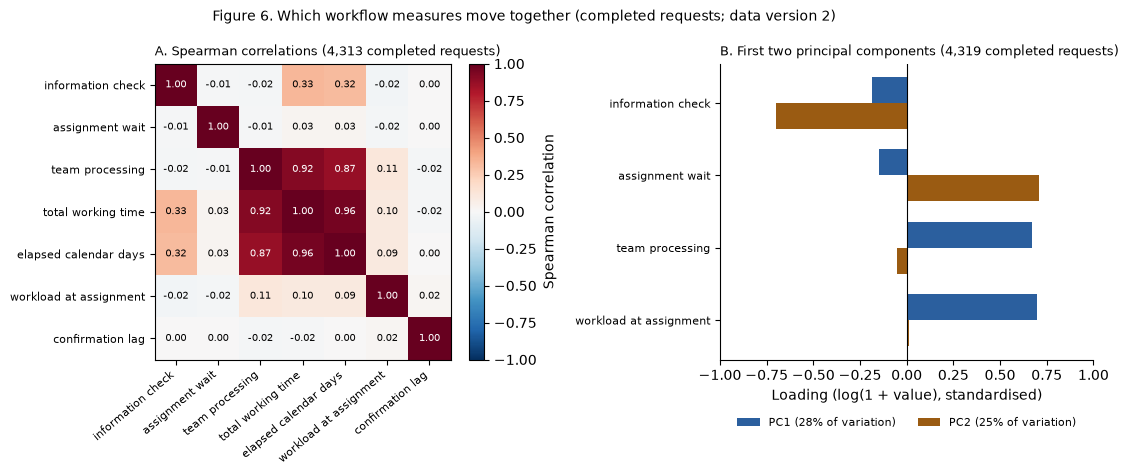

In [5]:
# Figure 6: Spearman correlations (A) and the loadings of the first two principal components (B)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.25, 1]})
im = ax1.imshow(corr.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax1.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right", fontsize=8)
ax1.set_yticks(range(len(corr)), corr.index, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iloc[i, j]
        ax1.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.6 else "black")
fig.colorbar(im, ax=ax1, fraction=0.046, pad=0.04, label="Spearman correlation")
ax1.set_title(f"A. Spearman correlations ({len(corr_data):,} completed requests)", fontsize=9, loc="left")
yy = np.arange(len(loadings))
for k, (pc, colour) in enumerate(zip(["PC1", "PC2"], ["#2b5f9e", "#9a5b12"])):
    ax2.barh(yy + (k - 0.5) * 0.36, loadings[pc], 0.36, color=colour,
             label=f"{pc} ({pca_summary.loc[pc, 'explained_variance_%']:.0f}% of variation)")
ax2.axvline(0, color="black", lw=0.8)
ax2.set_yticks(yy, loadings.index, fontsize=8)
ax2.invert_yaxis()
ax2.set_xlim(-1, 1)
ax2.set_xlabel("Loading (log(1 + value), standardised)")
ax2.set_title(f"B. First two principal components ({len(Z):,} completed requests)", fontsize=9, loc="left")
ax2.legend(fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
ax2.spines[["top", "right"]].set_visible(False)
fig.suptitle("Figure 6. Which workflow measures move together (completed requests; data version 2)", fontsize=10)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "workflow_relationships.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 6 caption.** *What it shows:* panel A gives Spearman rank correlations among seven workflow measures for the 4,313 completed requests with every measure (6 not yet confirmed by the extract are left out). Panel B gives the loadings of the first two principal components of the three stage times and workload at assignment (log(1 + value) of hours and of open tasks, standardised; all 4,319 completed requests), with the share of variation each accounts for. *Why it matters:* the three stage times show little monotonic association with one another (correlations between −0.02 and −0.01), and workload at assignment is only weakly related to team processing (0.11). Team processing and total working time are strongly correlated (0.92), but partly by construction: team processing makes up most of the total, which is the sum of the stages, and elapsed calendar days span the same interval (0.96 with total working time). The confirmation lag is unrelated to the other measures (correlations between −0.02 and 0.02). In the PCA, the four components account for similar shares of the variation (28.0%, 25.3%, 24.6% and 22.1%), close to the 25% each would take if the measures were unrelated, so no single combination stands out and the individual loadings should not be read as distinct patterns. *What it can't establish:* why the measures behave this way, or whether the same weak relationships would hold in a real workflow; rank correlations and components describe association in generated data, and the definitions tie some measures together by arithmetic.

**What section B shows.** Stage durations showed little monotonic association with one another. Workload at assignment had a weak positive association with team-processing time. The workflow measures do not reduce to a few shared patterns in these generated records, which is consistent with examining the stages separately, as notebooks 02 and 03 did; this analysis does not show that one approach is best.